Training Shape: (27455, 28, 28, 1)
Testing Shape: (7172, 28, 28, 1)
Number of Classes: 24


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)                    │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 24)                  │           3,096 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 226,840 (886.09 KB)

 Trainable params: 226,840 (886.09 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7152 - loss: 0.9575 - val_accuracy: 0.9581 - val_loss: 0.1720
Epoch 2/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9858 - loss: 0.0648 - val_accuracy: 0.9996 - val_loss: 0.0157
Epoch 3/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9996 - loss: 0.0084 - val_accuracy: 0.9818 - val_loss: 0.0609
Epoch 4/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9936 - loss: 0.0250 - val_accuracy: 1.0000 - val_loss: 0.0011
Epoch 5/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 1.0000 - loss: 7.9623e-04 - val_accuracy: 1.0000 - val_loss: 6.1582e-04
Epoch 6/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 1.0000 - loss: 4.7234e-04 - val_accuracy: 1.0000 - val_loss: 5.2459e-04
Epoch 7/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 1.0000 - loss: 2.9453e-04 - val_accuracy: 1.0000 - val_loss: 2.5233e-04
Epoch 8/10
773/773 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9864 - loss: 0

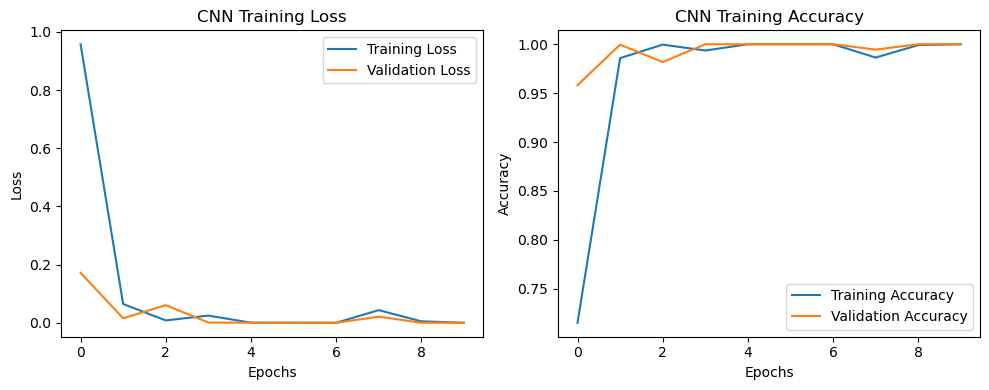

In [5]:
# Stage 1: Loading and Preprocessing Image Data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.optimizers import Adam

# Load Sign Language MNIST dataset
train = pd.read_csv("sign_mnist_train.csv")
test = pd.read_csv("sign_mnist_test.csv")

# Separate pixel values and labels
x_train = train.iloc[:, 1:].values
y_train = train.iloc[:, 0].values

x_test = test.iloc[:, 1:].values
y_test = test.iloc[:, 0].values

# Normalize pixel values
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Reshape images into 28 x 28 x 1
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

# Convert labels into continuous values from 0 to 23
classes = np.sort(np.unique(y_train))

y_train = np.searchsorted(classes, y_train)
y_test = np.searchsorted(classes, y_test)

print("Training Shape:", x_train.shape)
print("Testing Shape:", x_test.shape)
print("Number of Classes:", len(classes))


# Stage 2: Define CNN Architecture

model = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation="relu"),
    Dense(24, activation="softmax")
])

# Compile model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


# Stage 3: Train the Model

history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)


# Stage 4: Estimate Model Performance

loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)
print("Test Accuracy (%):", accuracy * 100)


# Plot Training Loss and Accuracy

plt.figure(figsize=(10, 4))

# Loss Graph
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("CNN Training Loss")
plt.legend()

# Accuracy Graph
plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("CNN Training Accuracy")
plt.legend()

plt.tight_layout()
plt.show()